In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

Мы будем работать с данными агрегатора такси [Sigma Cabs](https://www.kaggle.com/datasets/arashnic/taxi-pricing-with-mobility-analytics). В зависимости от характеристик поездки требуется предсказать один из трех типов повышенного ценообразования: [1, 2, 3]. Таким образом, это поможет компании оптимально мэтчить такси и клиентов. 

In [2]:
df = pd.read_csv('sigma_cabs.csv')
df.shape

(131662, 14)

In [3]:
# Занесем индекс колонку
df = df.set_index('Trip_ID')
df.head()

,Trip_Distance,Type_of_Cab,Customer_Since_Months,Life_Style_Index,Confidence_Life_Style_Index,Destination_Type,Customer_Rating,Cancellation_Last_1Month,Var1,Var2,Var3,Gender,Surge_Pricing_Type
Trip_ID,,,,,,,,,,,,,
T0005689460,6.77,B,1.0,2.42769,A,A,3.90500,0,40.0,46,60,Female,2
T0005689461,29.47,B,10.0,2.78245,B,A,3.45000,0,38.0,56,78,Male,2
T0005689464,41.58,NaN,10.0,NaN,NaN,E,3.50125,2,NaN,56,77,Male,2
T0005689465,61.56,C,10.0,NaN,NaN,A,3.45375,0,NaN,52,74,Male,3
T0005689467,54.95,C,10.0,3.03453,B,A,3.40250,4,51.0,49,102,Male,2


Описание признаков:

1. **Trip_ID**: ID for TRIP
2. **Trip_Distance**: The distance for the trip requested by the customer
3. **TypeofCab**: Category of the cab requested by the customer
4. **CustomerSinceMonths**: Customer using cab services since n months; 0 month means current month
5. **LifeStyleIndex**: Proprietary index created by Sigma Cabs showing lifestyle of the customer based on their behaviour
6. **ConfidenceLifeStyle_Index**: Category showing confidence on the index mentioned above
7. **Destination_Type**: Sigma Cabs divides any destination in one of the 14 categories.
8. **Customer_Rating**: Average of life time ratings of the customer till date
9. **CancellationLast1Month**: Number of trips cancelled by the customer in last 1 month
10. **Var1**, **Var2** and **Var3**: Continuous variables masked by the company. Can be used for modelling purposes
11. **Gender**: Gender of the customer

**SurgePricingType**: Target (can be of 3 types)


### EDA 
Заполните пропуски в вещественных признаках медианой, а в категориальных - самым популярным классом. Изобразите марицу корреляций и выведите топ5 пар самых коррелированных признаков.

Так как в сумме уникальных значений различных категориальных признаков окажется не супер-много, примените `One-Hot-Encoding` для них. Не забудьте в методе `pd.get_dummies` указать параметр `drop_first=True`.

In [8]:
### Your code is here
numeric_columns = df.loc[:,df.dtypes!=object].columns 
categorical_columns = df.loc[:,df.dtypes==object].columns
for col in numeric_columns:
    df[col] = df[col].fillna(df[col].mean())
for col in categorical_columns:
    most_recent = df.groupby(col).size().sort_values().index[-1]
    df[col] = df[col].fillna(most_recent)



Trip_Distance                  0
Type_of_Cab                    0
Customer_Since_Months          0
Life_Style_Index               0
Confidence_Life_Style_Index    0
Destination_Type               0
Customer_Rating                0
Cancellation_Last_1Month       0
Var1                           0
Var2                           0
Var3                           0
Gender                         0
Surge_Pricing_Type             0
dtype: int64

In [12]:
for col in categorical_columns:
    one_hot = pd.get_dummies(df[col], prefix=col, drop_first=True)     
    df = pd.concat((df.drop(col, axis=1), one_hot), axis=1)

In [13]:
df[numeric_columns].corr()

,Trip_Distance,Customer_Since_Months,Life_Style_Index,Customer_Rating,Cancellation_Last_1Month,Var1,Var2,Var3,Surge_Pricing_Type
Trip_Distance,1.000000,0.114340,0.468367,-0.054654,-0.007686,-0.030662,0.200456,0.231706,0.135928
Customer_Since_Months,0.114340,1.000000,0.119154,-0.049001,-0.006187,-0.006700,0.041766,0.110830,0.027202
Life_Style_Index,0.468367,0.119154,1.000000,0.189173,0.068176,-0.055873,0.215921,0.303296,-0.073682
Customer_Rating,-0.054654,-0.049001,0.189173,1.000000,0.003595,-0.007400,-0.302968,-0.227531,-0.155279
Cancellation_Last_1Month,-0.007686,-0.006187,0.068176,0.003595,1.000000,0.007550,0.095830,0.128686,0.185646
Var1,-0.030662,-0.006700,-0.055873,-0.007400,0.007550,1.000000,-0.031712,-0.041235,-0.026302
Var2,0.200456,0.041766,0.215921,-0.302968,0.095830,-0.031712,1.000000,0.683437,0.003437
Var3,0.231706,0.110830,0.303296,-0.227531,0.128686,-0.041235,0.683437,1.000000,-0.039309
Surge_Pricing_Type,0.135928,0.027202,-0.073682,-0.155279,0.185646,-0.026302,0.003437,-0.039309,1.000000


In [14]:
df.head(5)

,Trip_Distance,Customer_Since_Months,Life_Style_Index,Customer_Rating,Cancellation_Last_1Month,Var1,Var2,Var3,Surge_Pricing_Type,Type_of_Cab_B,...,Destination_Type_F,Destination_Type_G,Destination_Type_H,Destination_Type_I,Destination_Type_J,Destination_Type_K,Destination_Type_L,Destination_Type_M,Destination_Type_N,Gender_Male
Trip_ID,,,,,,,,,,,,,,,,,,,,,
T0005689460,6.77,1.0,2.427690,3.90500,0,40.000000,46,60,2,True,...,False,False,False,False,False,False,False,False,False,False
T0005689461,29.47,10.0,2.782450,3.45000,0,38.000000,56,78,2,True,...,False,False,False,False,False,False,False,False,False,True
T0005689464,41.58,10.0,2.802064,3.50125,2,64.202698,56,77,2,True,...,False,False,False,False,False,False,False,False,False,True
T0005689465,61.56,10.0,2.802064,3.45375,0,64.202698,52,74,3,False,...,False,False,False,False,False,False,False,False,False,True
T0005689467,54.95,10.0,3.034530,3.40250,4,51.000000,49,102,2,False,...,False,False,False,False,False,False,False,False,False,True


In [15]:

def get_redundant_pairs(df):
    pairs_to_drop = set()
    cols = df.columns
    for i in range(0, df.shape[1]):
        for j in range(0, i+1):
            pairs_to_drop.add((cols[i], cols[j]))
    return pairs_to_drop

def get_top_abs_correlations(df, n=5):
    au_corr = df.corr().abs().unstack()
    labels_to_drop = get_redundant_pairs(df)
    au_corr = au_corr.drop(labels=labels_to_drop).sort_values(ascending=False)
    return au_corr[0:n]

print("Top Absolute Correlations")
print(get_top_abs_correlations(df[numeric_columns], 10))

Top Absolute Correlations
Var2                      Var3                  0.683437
Trip_Distance             Life_Style_Index      0.468367
Life_Style_Index          Var3                  0.303296
Customer_Rating           Var2                  0.302968
Trip_Distance             Var3                  0.231706
Customer_Rating           Var3                  0.227531
Life_Style_Index          Var2                  0.215921
Trip_Distance             Var2                  0.200456
Life_Style_Index          Customer_Rating       0.189173
Cancellation_Last_1Month  Surge_Pricing_Type    0.185646
dtype: float64


### Training

In [17]:
np.random.seed(2022)

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [25]:
X = df.drop('Surge_Pricing_Type', axis=1)
y = df['Surge_Pricing_Type']
X_train, X_test, y_train, y_test  = train_test_split(X, y, 
                                                     test_size=0.2, 
                                                     shuffle=True, 
                                                     random_state=2022)

**Задание 1.** Обучите One-vs-Rest Logreg. Не забудьте в шаг добавить стандартизацию данных (через `StandardScaler`) Посчитайте precision, recall, f1-score и усредните по всем классам с помощью micro, macro и weighted avg. Здесь и далее округляйте до 3 знака после запятой.

Чтобы отдельно и долго не вычислять метрики, можно воспользоваться `classification_report` из `sklearn.metrics`!

In [27]:
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
### Your code is here
pipe = Pipeline([("scaler", StandardScaler()),
                 ("one_vs_all", OneVsRestClassifier(LogisticRegression()))])
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
print(classification_report(y_test, y_pred, digits=3))



              precision    recall  f1-score   support

           1      0.722     0.542     0.619      5372
           2      0.636     0.835     0.722     11349
           3      0.741     0.571     0.645      9612

    accuracy                          0.679     26333
   macro avg      0.700     0.649     0.662     26333
weighted avg      0.692     0.679     0.673     26333



Подберите оптимальные гиперпараметры модели с помощью `GridSearchCV()` из предложенных. Для лучшего набора гиперпараметров посчитайте те же самые метрики. Валидировать параметры необходимо по `accuracy`. В этот раз проведем настояющую процедуру Кросс-Валидации! 

Для этого в метод `fit` передадим тренировочную часть наших данных, в параметр `cv` ничего не будем передавать (по дефолту 5-fold Кросс-Валидация будет проведена), а итоговые метрики замерим на тесте!

In [29]:
param_grid = {'one_vs_all__estimator__penalty': ['l1', 'l2', 'elasticnet'],
              'one_vs_all__estimator__C': [0.001, 0.01, 0.1, 1]}

In [30]:
### Your code is here
from sklearn.model_selection import GridSearchCV

search = GridSearchCV(pipe, param_grid)

search.fit(X, y)

print(f"Best parameter (CV score={search.best_score_:.5f}):")
print(search.best_params_)


Best parameter (CV score=0.68088):
{'one_vs_all__estimator__C': 0.001, 'one_vs_all__estimator__penalty': 'l2'}


In [31]:


# Настраиваем модель с лучшими гиперпараметрами
pipe.set_params(**search.best_params_)

# Обучаем модель
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)

# Выводим отчет по классификации
print(classification_report(y_test, y_pred, digits=3))



              precision    recall  f1-score   support

           1      0.741     0.534     0.621      5372
           2      0.635     0.839     0.723     11349
           3      0.742     0.575     0.648      9612

    accuracy                          0.681     26333
   macro avg      0.706     0.650     0.664     26333
weighted avg      0.696     0.681     0.675     26333



Изобразите три калибровочные кривые для Logistic Classifier: 0-vs-rest, 1-vs-rest, 2-vs-rest. Хорошо ли откалиброван обученный классификатор? 

Заметьте, что `predict_proba` возвращает список из вероятностей для всех наших классов!

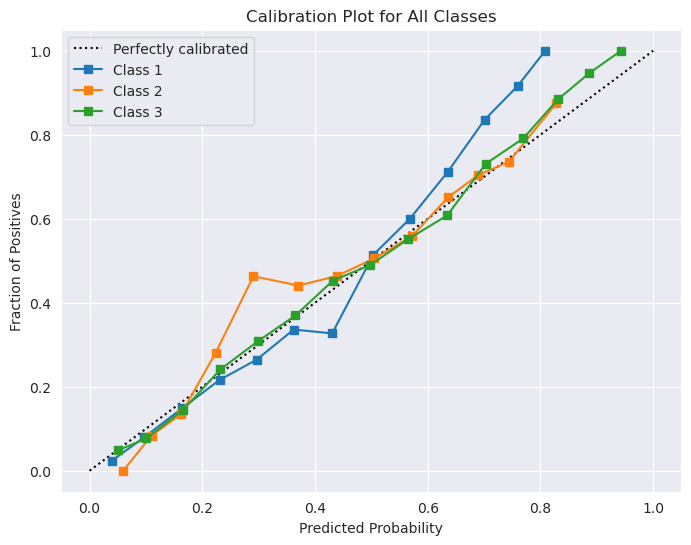

In [32]:
### Your code is here
import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay, calibration_curve

def Calibrator(X_test, y_test, estimator):
    y_pred = estimator.predict_proba(X_test)
    y_true = pd.get_dummies(y_test)

    # Создаем фигуру и оси для графиков
    fig, ax = plt.subplots(figsize=(8, 6))

    # Создаем калибровочные графики для каждого класса
    for klass in range(3):
        y_klass = np.array([])
        for i in range((y_pred.shape[0])):
            y_klass = np.append(y_klass, y_pred[i][klass])
        # Используем ax=ax для добавления графиков на общие оси
        CalibrationDisplay.from_predictions(y_true[klass+1], y_klass, n_bins=15, ax=ax, name=f'Class {klass+1}')

    # Добавляем легенду, заголовок и подписи осей
    ax.legend()
    ax.set_title('Calibration Plot for All Classes')
    ax.set_xlabel('Predicted Probability')
    ax.set_ylabel('Fraction of Positives')

    # Отображаем график
    plt.show()

# Вызываем функцию с моделью
Calibrator(X_test, y_test, search)

**Задание 2.** Обучите логистическую регрессию с гиперпараметрами из первого задания на полиномиальных признаках до 4 степени. Сравните метрики с первым заданием.


Пример: Пусть у нас был единственный признак 

$$
d_j = [1, 2, 3, 4]
$$

Тогда полиномиальные признаки до 4 степени от такого будут иметь вид:

$$
d_j^1 = [1, 2, 3, 4]
$$

$$
d_j^2 = [1, 4, 9, 16]
$$

$$
d_j^3 = [1, 8, 27, 64]
$$

$$
d_j^4 = [1, 16, 81, 256]
$$

P.S. Бинарные колонки нет смысла возводить в какие-то степени, поэтому возьмем исключительно вещественные из базовых. 

Для этого можно воспользоваться классическим циклом (или уроком из занятия про `Sberbank Housing Market`). Положите модифицированный датасет в переменную `X_polinomial`!

P.S.S Зачастую еще, создаваю полиномиальные фичи, учитывают "пересечения" признаков, то есть, например, из векторов признаков $d_j, d_i$ генерируют не просто новые степени $d_j^2, d_i^2, d_j^3, d_i^3...$, а еще и признаки вида $d_j \cdot d_i, d_j^2 \cdot d_i, d_j \cdot d_i^2...$, но здесь ограничьтесь просто степенями!

In [44]:
### Создание полиномиальных признаков

X_polinomial = X.copy()
numeric_columns = numeric_columns[0:-1]
numeric_columns

Index(['Trip_Distance', 'Customer_Since_Months', 'Life_Style_Index',
       'Customer_Rating', 'Cancellation_Last_1Month', 'Var1', 'Var2'],
      dtype='object')

In [45]:
for col in numeric_columns:
    for power in [2, 3, 4]:
        
        to_add = (X_polinomial[col]**power).to_frame().rename({col:f"{col}_{power}"}, axis=1)
        X_polinomial = pd.concat((X_polinomial, to_add), axis=1)

In [46]:
X_pol_train, X_pol_test, y_train, y_test  = train_test_split(X_polinomial, y, 
                                                             test_size=0.2, 
                                                             shuffle=True, 
                                                             random_state=2022)

In [47]:
### Your code is here
pipe.fit(X_pol_train, y_train)
y_pred = pipe.predict(X_pol_test)
print(classification_report(y_test, y_pred, digits=3))


              precision    recall  f1-score   support

           1      0.747     0.532     0.622      5372
           2      0.636     0.836     0.722     11349
           3      0.740     0.584     0.653      9612

    accuracy                          0.682     26333
   macro avg      0.708     0.651     0.666     26333
weighted avg      0.697     0.682     0.676     26333



По аналогии с первым заданием изобразите три калибровочные кривые. Стало ли лучше?

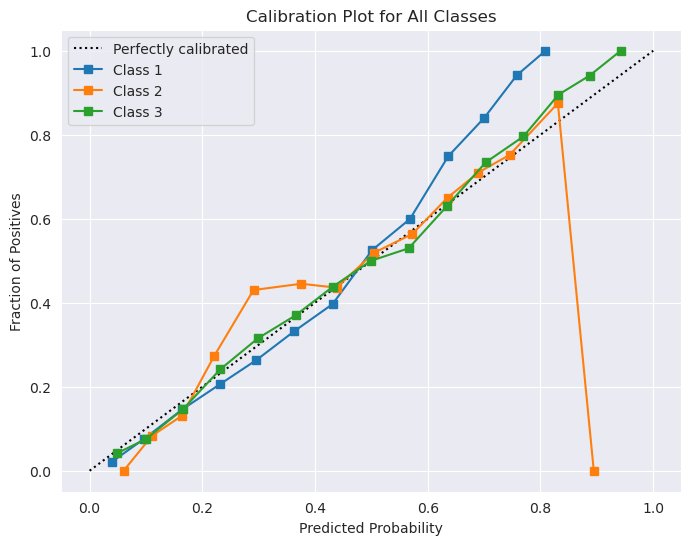

In [48]:
### Your code is here
pipe_poly = pipe
pipe_poly.fit(X_pol_train, y_train)

Calibrator(X_pol_test, y_test, pipe_poly)



**Задание 3.** Обучите на датасете без полиномиальных признаков One-vs-One `SGDClassifier` из `sklearn.linear_model`, который использует стохастический градиентный спуск (узнаете о нем позже) и может обучать как `SVM`, так и, например, `LogReg`, если указать в качестве параметра `loss` либо `hinge`, либо `log` соответственно!

Посчитайте precision, recall, f1-score и усредните по всем классам с помощью micro, macro и weighted avg.

In [49]:
X_train, X_test, y_train, y_test  = train_test_split(X, y, 
                                                     test_size=0.2, 
                                                     shuffle=True, 
                                                     random_state=2022)

In [50]:
from sklearn.linear_model import SGDClassifier
from sklearn.multiclass import OneVsOneClassifier

### Your code is here
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
sgd_clf = SGDClassifier(loss='hinge', random_state=42)
ovo_clf = OneVsOneClassifier(sgd_clf)
ovo_clf.fit(X_train_scaled, y_train)


OneVsOneClassifier(estimator=SGDClassifier(random_state=42))

In [51]:


# Делаем прогнозы
y_pred = ovo_clf.predict(X_test_scaled)
print(classification_report(y_test, y_pred, digits=3))



              precision    recall  f1-score   support

           1      0.738     0.528     0.615      5372
           2      0.625     0.864     0.725     11349
           3      0.754     0.533     0.624      9612

    accuracy                          0.675     26333
   macro avg      0.706     0.642     0.655     26333
weighted avg      0.695     0.675     0.666     26333



Подберите оптимальные гиперпараметры модели с помощью `GridSearchCV()`. При этом переберите всевозможные функции потерь. Таким образом, при `loss = 'hinge'`, мы обучим SVM, при `loss = 'log'` мы обучим логистическую регрессию и т.д.

Используйте прием с Кросс-Валидацией при подборе параметров, как ранее, а также замерьте метрики на тесте.

In [57]:
param_grid = {'one_vs_one__estimator__loss': ['hinge', 'log', 'modified_huber'],
              'one_vs_one__estimator__penalty': ['l1', 'l2'],
              'one_vs_one__estimator__alpha': [0.001, 0.01, 0.1]}

In [60]:
### Your code is here
# Создаем экземпляр StandardScaler
model = OneVsOneClassifier(SGDClassifier())

search = GridSearchCV(model, param_grid, n_jobs=-1)

search.fit(X_train_scaled, y_train)

print(f"Best parameter (CV score={search.best_score_:.5f}):")
print(search.best_params_)


Best parameter (CV score=0.68090):
{'estimator__alpha': 0.1, 'estimator__loss': 'modified_huber', 'estimator__penalty': 'l2'}


In [61]:
y_pred = search.predict(X_test_scaled)

# Выводим отчет по классификации
print(classification_report(y_test, y_pred, digits=3))


              precision    recall  f1-score   support

           1      0.746     0.529     0.619      5372
           2      0.632     0.845     0.723     11349
           3      0.745     0.569     0.645      9612

    accuracy                          0.680     26333
   macro avg      0.708     0.648     0.663     26333
weighted avg      0.697     0.680     0.674     26333



Можно ли однозначно сказать, какой подход оказался лучше: One-vs-Rest или One-vs-One?